# Imports

In [17]:
!pip install matplotlib

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)



[notice] A new release of pip is available: 24.3.1 -> 25.0.1
[notice] To update, run: pip install --upgrade pip


In [18]:
import pandas as pd
import json
import matplotlib.pyplot as plt
from transformers import BertTokenizerFast
import numpy as np

# Initialisation

In [19]:
# Read Data
with open("../output/evaluation_data.json", "r") as f:
    data = json.load(f)

df = pd.DataFrame(data)
df_retrieved = df[df["retrieved"] == True]
df_not_retrieved = df[df["retrieved"] == False]
df_top_10 = df_retrieved[df_retrieved["top10"] == True]
df_not_top_10 = df_retrieved[df_retrieved["top10"] == False]
df.head()


# Tokenizer
tokenizer = BertTokenizerFast.from_pretrained('bert-base-cased')

# Evaluations

## Set Evaluation

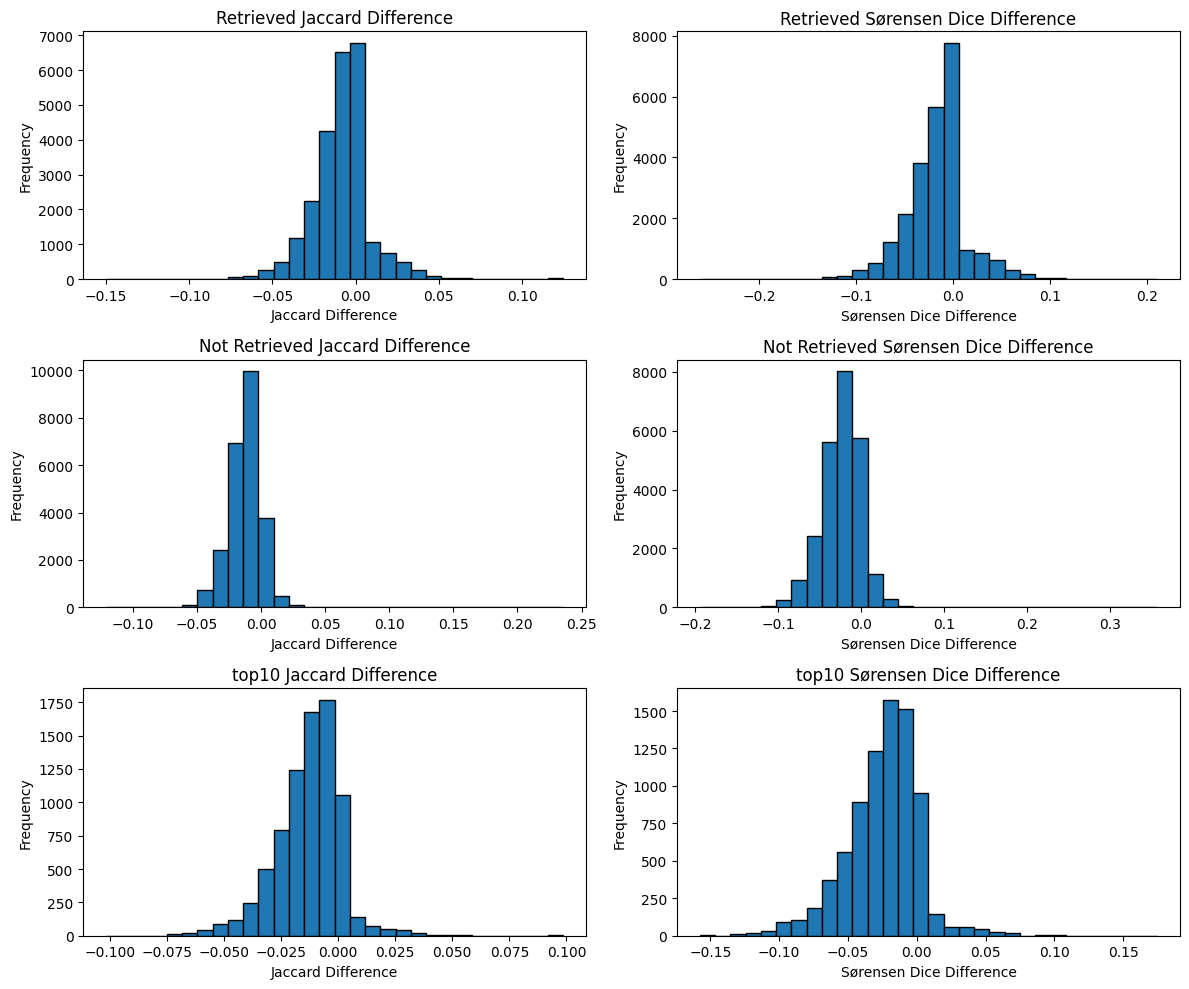

In [22]:
def jaccard(query, ori, attack):
    query_tok = set(tokenizer.tokenize(query))
    ori_tok = set(tokenizer.tokenize(ori))
    attack_tok = set(tokenizer.tokenize(attack))
    
    ori_intersection = query_tok.intersection(ori_tok)
    ori_union = query_tok.union(ori_tok)
    if len(ori_union) == 0:
        ori_jaccard = 0
    else:
        ori_jaccard = len(ori_intersection) / len(ori_union)
    
    attack_intersection = query_tok.intersection(attack_tok)
    attack_union = query_tok.union(attack_tok)
    if len(attack_union) == 0:
        attack_jaccard = 0
    else:
        attack_jaccard = len(attack_intersection) / len(attack_union)
    
    return ori_jaccard, attack_jaccard


def sorensen(query, ori, attack):
    query_tok = set(tokenizer.tokenize(query))
    ori_tok = set(tokenizer.tokenize(ori))
    attack_tok = set(tokenizer.tokenize(attack))
    
    size_ori = len(query_tok)+len(ori_tok)
    if size_ori == 0:
        ori_sorensen = 0
    else:
        ori_intersection = query_tok.intersection(ori_tok)
        ori_sorensen = 2*len(ori_intersection) / size_ori
    
    size_attack = len(query_tok)+len(attack_tok)
    if size_attack == 0:
        attack_sorensen = 0
    else:
        attack_intersection = query_tok.intersection(attack_tok)
        attack_sorensen = 2*len(attack_intersection) / size_attack
    
    return ori_sorensen, attack_sorensen


retrieved_jaccard_diff = []
retrieved_sorensen_diff = []
for _, row in df_retrieved.iterrows():
    ori_jaccard, attack_jaccard = jaccard(row["query"], row["original_doc"], row["attack_doc"])
    retrieved_jaccard_diff.append(ori_jaccard-attack_jaccard)
    ori_sorensen, attack_sorensen = sorensen(row["query"], row["original_doc"], row["attack_doc"])
    retrieved_sorensen_diff.append(ori_sorensen-attack_sorensen)

not_retrieved_jaccard_diff = []
not_retrieved_sorensen_diff = []
for _, row in df_not_retrieved.iterrows():
    ori_jaccard, attack_jaccard = jaccard(row["query"], row["original_doc"], row["attack_doc"])
    not_retrieved_jaccard_diff.append(ori_jaccard-attack_jaccard)
    ori_sorensen, attack_sorensen = sorensen(row["query"], row["original_doc"], row["attack_doc"])
    not_retrieved_sorensen_diff.append(ori_sorensen-attack_sorensen)
    
top10_jaccard_diff = []
top10_sorensen_diff = []
for _, row in df_top_10.iterrows():
    ori_jaccard, attack_jaccard = jaccard(row["query"], row["original_doc"], row["attack_doc"])
    top10_jaccard_diff.append(ori_jaccard-attack_jaccard)
    ori_sorensen, attack_sorensen = sorensen(row["query"], row["original_doc"], row["attack_doc"])
    top10_sorensen_diff.append(ori_sorensen-attack_sorensen)

fig, axs = plt.subplots(3, 2, figsize=(12, 10))

axs[0, 0].hist(retrieved_jaccard_diff, bins=30, edgecolor='black')
axs[0, 0].set_title("Retrieved Jaccard Difference")
axs[0, 0].set_xlabel("Jaccard Difference")
axs[0, 0].set_ylabel("Frequency")

axs[0, 1].hist(retrieved_sorensen_diff, bins=30, edgecolor='black')
axs[0, 1].set_title("Retrieved Sørensen Dice Difference")
axs[0, 1].set_xlabel("Sørensen Dice Difference")
axs[0, 1].set_ylabel("Frequency")

axs[1, 0].hist(not_retrieved_jaccard_diff, bins=30, edgecolor='black')
axs[1, 0].set_title("Not Retrieved Jaccard Difference")
axs[1, 0].set_xlabel("Jaccard Difference")
axs[1, 0].set_ylabel("Frequency")

axs[1, 1].hist(not_retrieved_sorensen_diff, bins=30, edgecolor='black')
axs[1, 1].set_title("Not Retrieved Sørensen Dice Difference")
axs[1, 1].set_xlabel("Sørensen Dice Difference")
axs[1, 1].set_ylabel("Frequency")

axs[2, 0].hist(top10_jaccard_diff, bins=30, edgecolor='black')
axs[2, 0].set_title("top10 Jaccard Difference")
axs[2, 0].set_xlabel("Jaccard Difference")
axs[2, 0].set_ylabel("Frequency")

axs[2, 1].hist(top10_sorensen_diff, bins=30, edgecolor='black')
axs[2, 1].set_title("top10 Sørensen Dice Difference")
axs[2, 1].set_xlabel("Sørensen Dice Difference")
axs[2, 1].set_ylabel("Frequency")

# Adjust layout to prevent overlap and display the plots
plt.tight_layout()
plt.show()

## Rank-ups

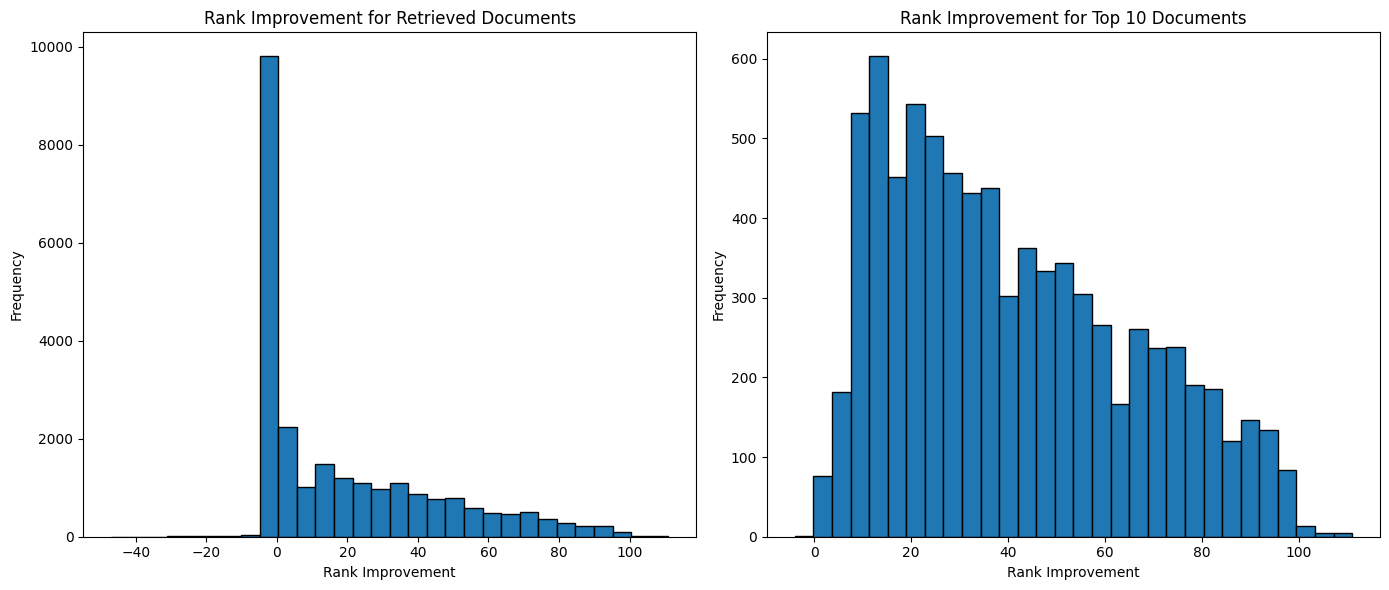

In [23]:
retrieved_rank_improvements = df_retrieved["rank_improvement"]
top10_rank_improvements = df_top_10["rank_improvement"]

fig, axs = plt.subplots(1, 2, figsize=(14, 6))

axs[0].hist(retrieved_rank_improvements, bins=30, edgecolor='black')
axs[0].set_title("Rank Improvement for Retrieved Documents")
axs[0].set_xlabel("Rank Improvement")
axs[0].set_ylabel("Frequency")

axs[1].hist(top10_rank_improvements, bins=30, edgecolor='black')
axs[1].set_title("Rank Improvement for Top 10 Documents")
axs[1].set_xlabel("Rank Improvement")
axs[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [26]:
retrieved_rank_improvements_median = df_retrieved["rank_improvement"].median()
top10_rank_improvements_median = df_top_10["rank_improvement"].median()
retrieved_rank_improvements_mean = df_retrieved["rank_improvement"].mean()
top10_rank_improvements_mean = df_top_10["rank_improvement"].mean()
print("Retrieved Rank Improvement Median: " + str(retrieved_rank_improvements_median))
print("Top 10 Rank Improvement Median: " + str(top10_rank_improvements_median))
print("Retrieved Rank Improvement Mean: " + str(retrieved_rank_improvements_mean))
print("Top 10 rank Improvement Mean: " + str(top10_rank_improvements_mean))

Retrieved Rank Improvement Median: 7.0
Top 10 Rank Improvement Median: 36.0
Retrieved Rank Improvement Mean: 19.651530550022358
Top 10 rank Improvement Mean: 40.64931783729156


In [28]:
print("Top 10 Rate: ", len(df_top_10) / len(df_retrieved))
print("Improved to Top 10 Rate: ", len(df_top_10) / len(df_retrieved[df_retrieved["rank_improvement"] > 0]))

Top 10 Rate:  0.32180169925606733
Improved to Top 10 Rate:  0.537443139384887
